# Pretrain model yolo26n-seg

## SetUp

### Import Library

In [198]:
from glob import glob
import cv2
import numpy as np
import os
import matplotlib.pyplot as plt 
from ultralytics import YOLO
from roboflow import Roboflow
from dotenv import load_dotenv

### Set SEED

In [190]:
SEED = 2345

os.environ['PYTHONHASHSEED'] = str(SEED)

### Load .env

In [199]:
load_dotenv()

robowflow_api_key = os.getenv("ROBOWFLOW_API_KEY")

## Crop Image for labels Datasets 

In [191]:
def load_fish_image(filepath="../data/test_fish/*.jpg"):
  files = sorted(glob(filepath), key=lambda x: int(x.split("-")[-1].split(".")[0]))
  images = []

  for file in files:
    fish_img = cv2.imread(file)
    if fish_img is not None:
      fish_rgb = cv2.cvtColor(fish_img, cv2.COLOR_BGR2RGB)
      # print(f"Loaded: {file} | Shape: {fish_rgb.shape}")
      file_name = file.split("/")[-1].split(".")[0]
      h, w, _ = fish_rgb.shape
      images.append({"name": file_name, 
                     "height": h,
                     "width": w,
                     "pixel_array": fish_rgb})
    else:
      print(f"Warning: Dowload {file} fail!!!")

  return images  

In [192]:
def crops_fish_image(crop_size=640, crops_per_img=2):
  images = load_fish_image()

  cropped_images = []

  rng = np.random.default_rng(seed=SEED)

  output_dir = "../data/fish_cropped_image"
  os.makedirs(output_dir, exist_ok=True)

  for image in images:
    if image["height"] < crop_size or image["width"] < crop_size:
      continue

    for crop_idx in range(1, crops_per_img + 1):
      max_y = image["height"] - crop_size
      max_x = image["width"] - crop_size

      start_y = rng.integers(0, max_y)
      start_x = rng.integers(0, max_x)

      cropped_img = image["pixel_array"][start_y:start_y + crop_size, start_x:start_x + crop_size]
      name = f"{image["name"]}_{crop_idx}"

      cropped_images.append({"name": name, "pixel_array": cropped_img})

  total_crops = len(cropped_images)

  if total_crops == 0:
    return

  ncols = 4
  nrows = (np.ceil(total_crops / ncols)).astype(int)

  fig, axes = plt.subplots(nrows=nrows, ncols=ncols, figsize=(15, nrows * 3.5))
  axes = axes.flatten()

  for i in range(total_crops):
    crop = cropped_images[i]["pixel_array"]
    name = cropped_images[i]["name"]
    
    axes[i].imshow(crop)
    axes[i].set_title(name, fontsize=10)
    axes[i].axis('off')

    save_img = cv2.cvtColor(crop, cv2.COLOR_RGB2BGR)

    output_path = os.path.join(output_dir, f"{name}.jpg")
    success = cv2.imwrite(output_path, save_img)

    if not success:
      print(f"[Warning] can't save this file: {output_path}")
      print(f"  Shape: {save_img.shape}, Dtype: {save_img.dtype}")

  for j in range(total_crops, len(axes)):
    axes[j].axis('off')

  plt.tight_layout()
  plt.show()

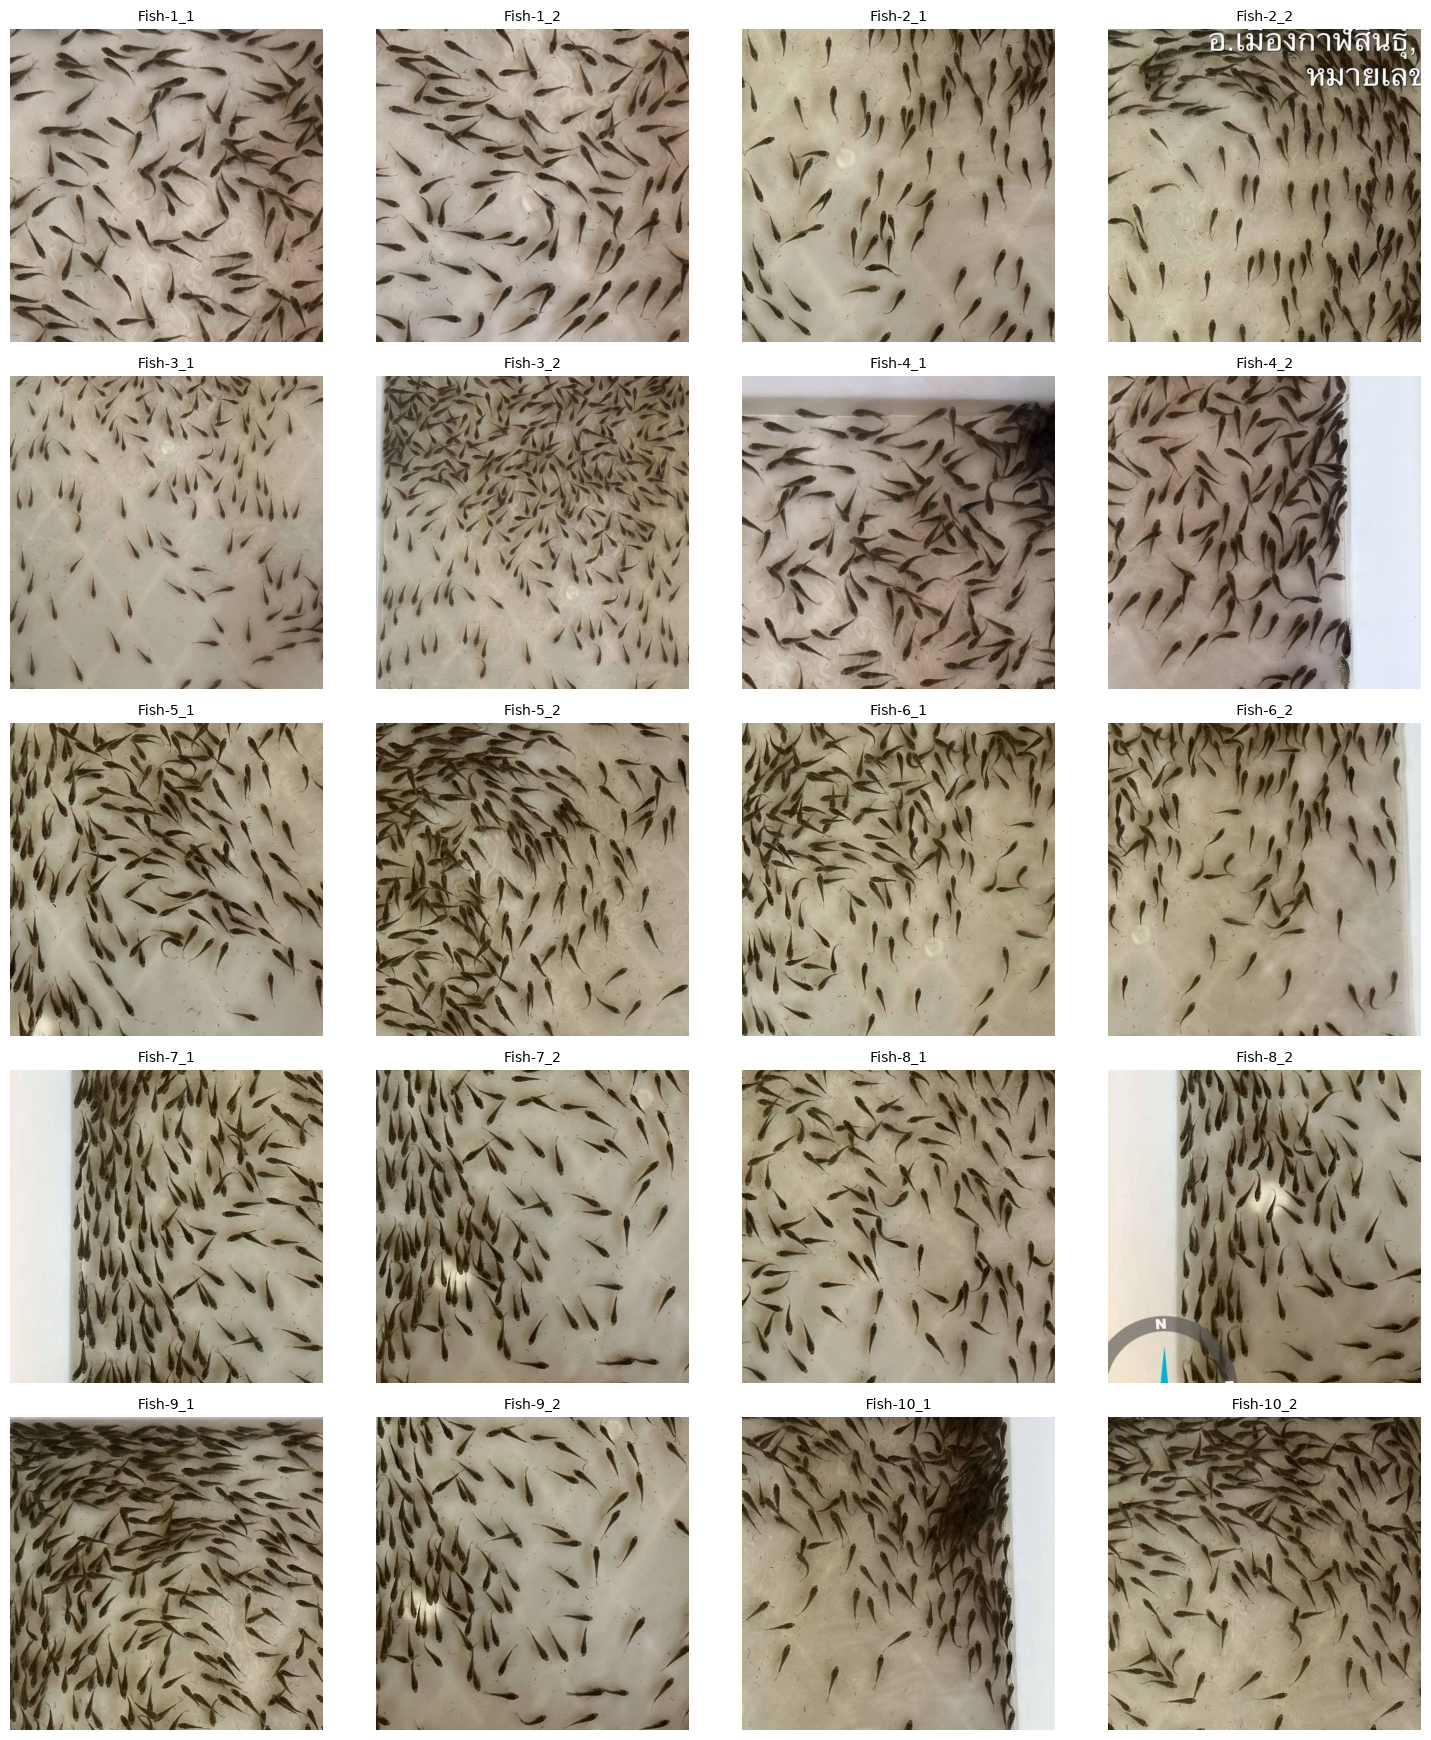

In [194]:
crops_fish_image()

## Train with 5 images

### Dowload dataset from roblowflow


Dataset: ../data/fish_dataset_5_images <br>
Train: 13 images | Val: 1 image <br>
Data Augmentation:
- Outputs per training example: 3
- Flip: Horizontal, Vertical
- Rotation: Between -15° and +15°
- Grayscale: Apply to 15% of images
- Brightness: Between -25% and +25%
- Blur: Up to 4px
- Noise: Up to 1.96% of pixels

In [202]:
rf = Roboflow(api_key=robowflow_api_key)
project = rf.workspace("phitchakorns-workspace").project("fish_count-ekvlc")
version = project.version(3)
dataset = version.download(
  model_format="coco-segmentation",
  location="../data/fish_dataset_5_images"
  )

loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to ../data/fish_dataset_5_images in coco-segmentation:: 100%|██████████| 16/16 [00:00<00:00, 639.36it/s]
